## 1. Setup

In [ ]:
import os, sys, json, random, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score

sns.set_theme(style="whitegrid")

try:                                           # running in Google Colab
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/SER"
except ImportError:                            # running locally from the notebooks/ folder
    ROOT = ".."
assert os.path.isdir(ROOT), f"Folder not found: {ROOT}. Create MyDrive/SER and upload the files (see instructions above)."
sys.path.insert(0, ROOT)
DATA = f"{ROOT}/data"
OUT = f"{ROOT}/cnn_outputs"
os.makedirs(OUT, exist_ok=True)

from ser_audio import EMOTIONS, N_MELS, N_FRAMES
from ser_cnn import SERCNN, spec_augment, save_checkpoint, load_checkpoint

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "NO GPU")
if device.type != "cuda":
    print("WARNING: no GPU. In Colab use Runtime > Change runtime type > T4 GPU. (CPU works but is slow.)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
torch 2.14.1+cu130 | device: cuda | Tesla T4


## 2. Load the Phase 1 data



In [ ]:
X = np.load(f"{DATA}/X_logmel_norm.npy")                 # (n_clips, 128, 173), already normalized
labels = pd.read_csv(f"{DATA}/labels.csv")
norm_mean, norm_std = np.load(f"{DATA}/norm_stats.npy")
print("X:", X.shape, X.dtype, "| labels:", labels.shape, "| train mean/std:", round(float(norm_mean), 3), round(float(norm_std), 3))

assert X.shape[0] == len(labels), "array and labels have different lengths"
assert X.shape[1:] == (N_MELS, N_FRAMES), "unexpected spectrogram shape"
assert list(labels["emotion"].map(EMOTIONS.index)) == list(labels["label"]), "label ids do not match the emotion order"

is_train = (labels["split"] == "train").values
is_val = (labels["split"] == "val").values
print("train clips:", is_train.sum(), "| val clips:", is_val.sum())
print("train actors:", sorted(labels.loc[is_train, "actor"].unique()))
print("val actors:  ", sorted(labels.loc[is_val, "actor"].unique()))
assert set(labels.loc[is_train, "actor"]).isdisjoint(labels.loc[is_val, "actor"]), "actor overlap between train and val!"

def make_tensors(mask):
    xs = torch.from_numpy(X[mask][:, None, :, :]).float()            # add channel axis -> (n, 1, 128, 173)
    ys = torch.from_numpy(labels.loc[mask, "label"].values).long()
    return xs.to(device), ys.to(device)

Xtr, ytr = make_tensors(is_train)
Xva, yva = make_tensors(is_val)
print("train tensor:", tuple(Xtr.shape), "| val tensor:", tuple(Xva.shape))

X: (1439, 128, 173) float32 | labels: (1439, 8) | train mean/std: -17.165 15.781
train clips: 899 | val clips: 240
train actors: [np.int64(2), np.int64(4), np.int64(5), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(13), np.int64(14), np.int64(16), np.int64(18), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]
val actors:   [np.int64(3), np.int64(6), np.int64(15), np.int64(20)]
train tensor: (899, 1, 128, 173) | val tensor: (240, 1, 128, 173)


## 3. Handle class imbalance



In [ ]:
counts = np.bincount(labels.loc[is_train, "label"].values, minlength=len(EMOTIONS))
weights = counts.sum() / (len(EMOTIONS) * counts)
class_weights = torch.tensor(weights, dtype=torch.float32, device=device)
print(pd.DataFrame({"emotion": EMOTIONS, "train_clips": counts, "class_weight": weights.round(3)}).to_string(index=False))

  emotion  train_clips  class_weight
  neutral           60         1.873
     calm          120         0.936
    happy          119         0.944
      sad          120         0.936
    angry          120         0.936
  fearful          120         0.936
  disgust          120         0.936
surprised          120         0.936


## 4. The model and SpecAugment

The model (`SERCNN`, in `ser_cnn.py`) has 4 convolution blocks. Each block is **Conv -> BatchNorm -> ReLU -> MaxPool -> Dropout**. At the end the feature maps are pooled and a dropout + linear layer gives 8 scores, one per emotion.

**SpecAugment** blanks out random frequency bands and time spans of the training spectrograms, so the network cannot rely on one small region. It is applied to **training batches only**.

In [ ]:
import inspect
print(inspect.getsource(SERCNN))
demo = SERCNN().to(device)
print("parameters:", sum(p.numel() for p in demo.parameters()))
print("output shape for a batch of 4:", tuple(demo(Xtr[:4]).shape))      # expect (4, 8)

class SERCNN(nn.Module):
    """Small CNN for 1 x 128 x 173 log-mel spectrograms.

    Each block:  Conv3x3 -> BatchNorm -> ReLU -> MaxPool(2) -> Dropout2d
    Head:        [global average pool ++ global max pool] -> Dropout -> Linear(n_classes)

    channels : output channels of each conv block (3 or 4 blocks are sensible)
    dropout  : final dropout; the dropout inside the blocks is half of it
    """

    def __init__(self, n_classes=8, channels=(32, 64, 128, 128), dropout=0.3):
        super().__init__()
        layers, c_in = [], 1
        for c_out in channels:
            layers += [
                nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(c_out),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
                nn.Dropout2d(dropout * 0.5),
            ]
            c_in = c_out
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * c_in, n_clas

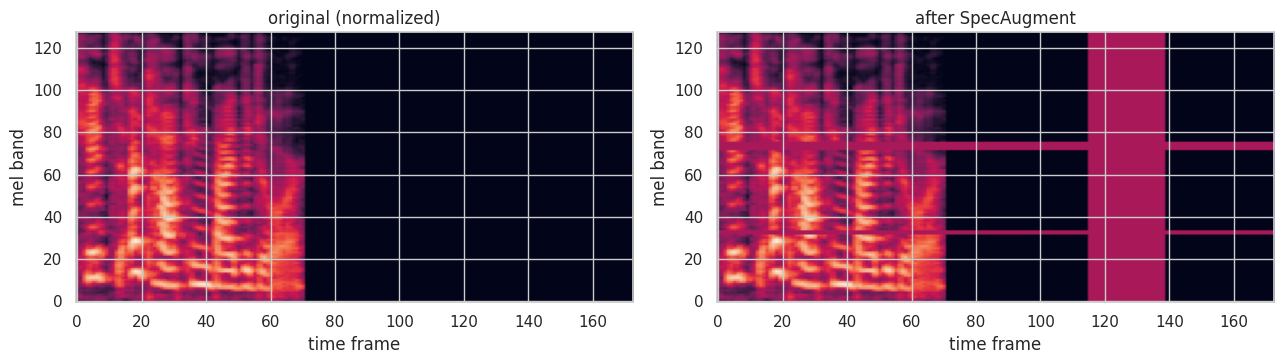

In [ ]:
# what SpecAugment does to one training spectrogram
random.seed(1)
orig = Xtr[:1]
aug = spec_augment(orig)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, img, t in zip(axes, (orig, aug), ("original (normalized)", "after SpecAugment")):
    ax.imshow(img[0, 0].cpu().numpy(), origin="lower", aspect="auto"); ax.set_title(t)
    ax.set_xlabel("time frame"); ax.set_ylabel("mel band")
plt.tight_layout(); plt.show()

## 5. Training function

For each epoch the model trains on the training clips, then is scored on the validation clips. We use:
- **AdamW** optimizer with weight decay (a mild penalty on large weights).
- **Weighted cross-entropy loss** (class weights from section 3).
- **Learning-rate scheduler** (`ReduceLROnPlateau`): halves the learning rate when validation macro-F1 stops improving.
- **Early stopping:** stop when validation macro-F1 has not improved for `PATIENCE` epochs, then restore the best epoch.

Model selection uses **validation macro-F1**, never the test set.

In [ ]:
QUICK = False        # True = fast dry run (2 configs, 3 epochs). Set to False for the real training.

BATCH = 32
MAX_EPOCHS = 3 if QUICK else 60
PATIENCE = 12            # early stopping: epochs without improvement
LR_PATIENCE = 5          # scheduler: epochs without improvement before lr is halved
SEEDS = [0] if QUICK else [0, 1, 2]

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

@torch.no_grad()
def predict_logits(model, xs, batch=128):
    model.eval()
    return torch.cat([model(xs[i:i + batch]) for i in range(0, len(xs), batch)])

def evaluate_split(model, xs, ys, criterion):
    logits = predict_logits(model, xs)
    loss = criterion(logits, ys).item()
    pred, true = logits.argmax(1).cpu().numpy(), ys.cpu().numpy()
    return loss, accuracy_score(true, pred), f1_score(true, pred, average="macro")

def train_model(cfg, seed, max_epochs=None, verbose=True):
    max_epochs = max_epochs or MAX_EPOCHS
    set_seed(seed)
    model = SERCNN(len(EMOTIONS), tuple(cfg["channels"]), cfg["dropout"]).to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=cfg.get("label_smoothing", 0.0))
    val_criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=LR_PATIENCE)

    best = {"f1": -1.0, "epoch": 0, "state": None}
    history, bad_epochs = [], 0
    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(len(Xtr), device=device)
        run_loss, correct, seen = 0.0, 0, 0
        for i in range(0, len(perm) - BATCH + 1, BATCH):          # full batches only
            idx = perm[i:i + BATCH]
            xb, yb = Xtr[idx], ytr[idx]
            if cfg["specaug"]:
                xb = spec_augment(xb)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * len(idx); correct += (logits.argmax(1) == yb).sum().item(); seen += len(idx)

        val_loss, val_acc, val_f1 = evaluate_split(model, Xva, yva, val_criterion)
        scheduler.step(val_f1)
        history.append({"epoch": epoch, "train_loss": run_loss / seen, "train_acc": correct / seen,
                        "val_loss": val_loss, "val_acc": val_acc, "val_macro_f1": val_f1,
                        "lr": optimizer.param_groups[0]["lr"]})
        if val_f1 > best["f1"] + 1e-4:
            best = {"f1": val_f1, "epoch": epoch, "acc": val_acc,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
            bad_epochs = 0
        else:
            bad_epochs += 1
        if verbose and (epoch % 5 == 0 or epoch == 1):
            print(f"  epoch {epoch:3d} | train loss {run_loss/seen:.3f} acc {correct/seen:.3f} | "
                  f"val loss {val_loss:.3f} acc {val_acc:.3f} F1 {val_f1:.3f} | lr {optimizer.param_groups[0]['lr']:.1e}")
        if bad_epochs >= PATIENCE:
            if verbose: print(f"  early stopping at epoch {epoch} (best epoch {best['epoch']})")
            break

    model.load_state_dict(best["state"])          # go back to the best epoch
    return model, pd.DataFrame(history), best
print("training function ready | QUICK =", QUICK)

training function ready | QUICK = False


## 6. Hyperparameter tuning (validation data only)

We start from a base configuration and change **one thing at a time**, so we can see what helps:

| Run | What changes |
|---|---|
| base | 4 blocks (32-64-128-128), dropout 0.3, lr 1e-3, weight decay 1e-4, SpecAugment on |
| no_specaug | SpecAugment off (shows what augmentation gives us) |
| dropout_0.5 | more dropout |
| lr_3e-4 | smaller learning rate |
| wd_1e-3 | stronger weight decay |
| smooth_0.1 | label smoothing 0.1 |
| 3_blocks | only 3 conv blocks (32-64-128) |
| wider | wider network (64-128-256-256) |

The run with the highest **validation macro-F1** is chosen. Results are saved after every run, so a Colab disconnect does not lose everything.

In [ ]:
BASE = dict(channels=(32, 64, 128, 128), dropout=0.3, lr=1e-3, weight_decay=1e-4, specaug=True, label_smoothing=0.0)
VARIANTS = {
    "base": {},
    "no_specaug": dict(specaug=False),
    "dropout_0.5": dict(dropout=0.5),
    "lr_3e-4": dict(lr=3e-4),
    "wd_1e-3": dict(weight_decay=1e-3),
    "smooth_0.1": dict(label_smoothing=0.1),
    "3_blocks": dict(channels=(32, 64, 128)),
    "wider": dict(channels=(64, 128, 256, 256)),
}
if QUICK:
    VARIANTS = dict(list(VARIANTS.items())[:2])

tuning_rows, configs = [], {}
for name, change in VARIANTS.items():
    cfg = {**BASE, **change}
    configs[name] = cfg
    print(f"\n=== {name}: {change if change else 'base config'}")
    t0 = time.time()
    _, hist, best = train_model(cfg, seed=0)
    tuning_rows.append({"run": name, "val_macro_f1": best["f1"], "val_acc": best["acc"], "best_epoch": best["epoch"],
                        "epochs_run": len(hist), "minutes": round((time.time() - t0) / 60, 1), "change": str(change) if change else "base"})
    pd.DataFrame(tuning_rows).to_csv(f"{OUT}/tuning_results.csv", index=False)     # saved after every run

tuning = pd.DataFrame(tuning_rows).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
tuning


=== base: base config
  epoch   1 | train loss 2.460 acc 0.125 | val loss 2.064 acc 0.100 F1 0.057 | lr 1.0e-03
  epoch   5 | train loss 2.132 acc 0.153 | val loss 1.961 acc 0.267 F1 0.196 | lr 1.0e-03
  epoch  10 | train loss 1.974 acc 0.214 | val loss 1.908 acc 0.204 F1 0.153 | lr 1.0e-03
  epoch  15 | train loss 1.874 acc 0.251 | val loss 1.731 acc 0.367 F1 0.316 | lr 1.0e-03
  epoch  20 | train loss 1.833 acc 0.289 | val loss 1.769 acc 0.304 F1 0.260 | lr 1.0e-03
  epoch  25 | train loss 1.750 acc 0.311 | val loss 1.622 acc 0.400 F1 0.371 | lr 1.0e-03
  epoch  30 | train loss 1.657 acc 0.354 | val loss 1.676 acc 0.358 F1 0.332 | lr 1.0e-03
  epoch  35 | train loss 1.628 acc 0.353 | val loss 1.588 acc 0.371 F1 0.352 | lr 1.0e-03
  epoch  40 | train loss 1.525 acc 0.401 | val loss 1.500 acc 0.429 F1 0.407 | lr 5.0e-04
  epoch  45 | train loss 1.485 acc 0.410 | val loss 1.484 acc 0.446 F1 0.438 | lr 5.0e-04
  epoch  50 | train loss 1.414 acc 0.455 | val loss 1.407 acc 0.504 F1 0.483 

,run,val_macro_f1,val_acc,best_epoch,epochs_run,minutes,change
0,no_specaug,0.542304,0.558333,55,60,0.9,{'specaug': False}
1,wider,0.518635,0.533333,53,60,2.0,"{'channels': (64, 128, 256, 256)}"
2,smooth_0.1,0.517290,0.537500,59,60,1.0,{'label_smoothing': 0.1}
3,wd_1e-3,0.498040,0.508333,56,60,1.0,{'weight_decay': 0.001}
4,base,0.485821,0.508333,55,60,1.0,base
5,3_blocks,0.431812,0.445833,50,60,0.9,"{'channels': (32, 64, 128)}"
6,lr_3e-4,0.413241,0.437500,42,54,0.9,{'lr': 0.0003}
7,dropout_0.5,0.275741,0.275000,35,47,0.8,{'dropout': 0.5}


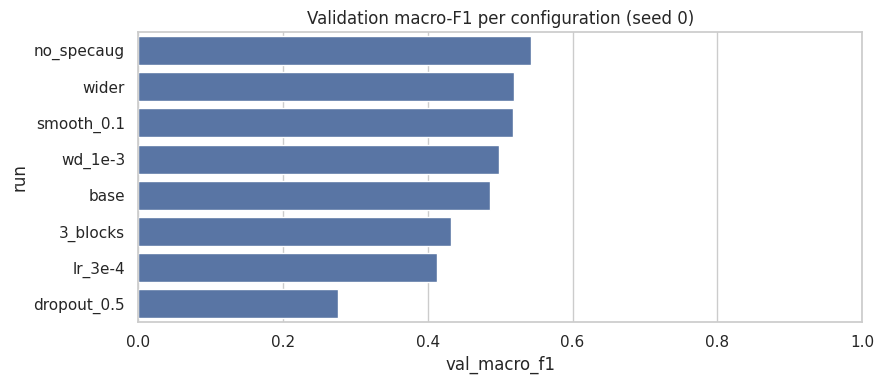

Chosen configuration: no_specaug {'channels': (32, 64, 128, 128), 'dropout': 0.3, 'lr': 0.001, 'weight_decay': 0.0001, 'specaug': False, 'label_smoothing': 0.0}


In [ ]:
plt.figure(figsize=(9, 4))
sns.barplot(data=tuning, y="run", x="val_macro_f1", color="#4C72B0")
plt.xlim(0, 1); plt.title("Validation macro-F1 per configuration (seed 0)")
plt.tight_layout(); plt.savefig(f"{OUT}/tuning_val_f1.png", dpi=140); plt.show()

best_run = tuning.loc[0, "run"]
best_cfg = configs[best_run]
print("Chosen configuration:", best_run, best_cfg)

**How to read this:** the validation set is only 4 actors (240 clips), so differences of 1-2 points between runs are within noise. Prefer a clear winner; if several runs are close, that is fine, the choice does not matter much.

## 7. Train the final model with 3 seeds

Neural networks give slightly different results for different random seeds. We train the chosen configuration with 3 seeds, and keep the seed with the best **validation** macro-F1 as the final model. (In the evaluation notebook we will also report how much the seeds differ.)

In [ ]:
final = []
for seed in SEEDS:
    print(f"\n=== final training, seed {seed}")
    model, hist, best = train_model(best_cfg, seed=seed)
    ck = f"{OUT}/cnn_seed{seed}.pt"
    save_checkpoint(ck, model, best_cfg, norm_mean, norm_std,
                    extra={"seed": seed, "val_macro_f1": best["f1"], "val_accuracy": best["acc"], "best_epoch": best["epoch"]})
    hist.to_csv(f"{OUT}/history_seed{seed}.csv", index=False)
    final.append({"seed": seed, "val_macro_f1": best["f1"], "val_acc": best["acc"], "best_epoch": best["epoch"], "history": hist, "ckpt": ck})
    print(f"  saved {ck} | val macro-F1 {best['f1']:.3f}")

chosen = max(final, key=lambda r: r["val_macro_f1"])
print("\nSeeds:", [(r["seed"], round(r["val_macro_f1"], 3)) for r in final])
print("Chosen seed (best validation macro-F1):", chosen["seed"])


=== final training, seed 0
  epoch   1 | train loss 2.398 acc 0.116 | val loss 2.055 acc 0.100 F1 0.053 | lr 1.0e-03
  epoch   5 | train loss 2.058 acc 0.174 | val loss 1.886 acc 0.317 F1 0.249 | lr 1.0e-03
  epoch  10 | train loss 1.760 acc 0.314 | val loss 1.746 acc 0.312 F1 0.268 | lr 1.0e-03
  epoch  15 | train loss 1.622 acc 0.371 | val loss 1.553 acc 0.467 F1 0.416 | lr 1.0e-03
  epoch  20 | train loss 1.482 acc 0.415 | val loss 1.530 acc 0.475 F1 0.469 | lr 1.0e-03
  epoch  25 | train loss 1.428 acc 0.436 | val loss 1.480 acc 0.408 F1 0.364 | lr 1.0e-03
  epoch  30 | train loss 1.215 acc 0.517 | val loss 1.449 acc 0.508 F1 0.488 | lr 5.0e-04
  epoch  35 | train loss 1.139 acc 0.571 | val loss 1.475 acc 0.483 F1 0.461 | lr 5.0e-04
  epoch  40 | train loss 1.110 acc 0.610 | val loss 1.446 acc 0.512 F1 0.501 | lr 5.0e-04
  epoch  45 | train loss 1.004 acc 0.610 | val loss 1.433 acc 0.529 F1 0.516 | lr 5.0e-04
  epoch  50 | train loss 0.957 acc 0.652 | val loss 1.454 acc 0.521 F1 0

## 8. Save the final model, training history and curves

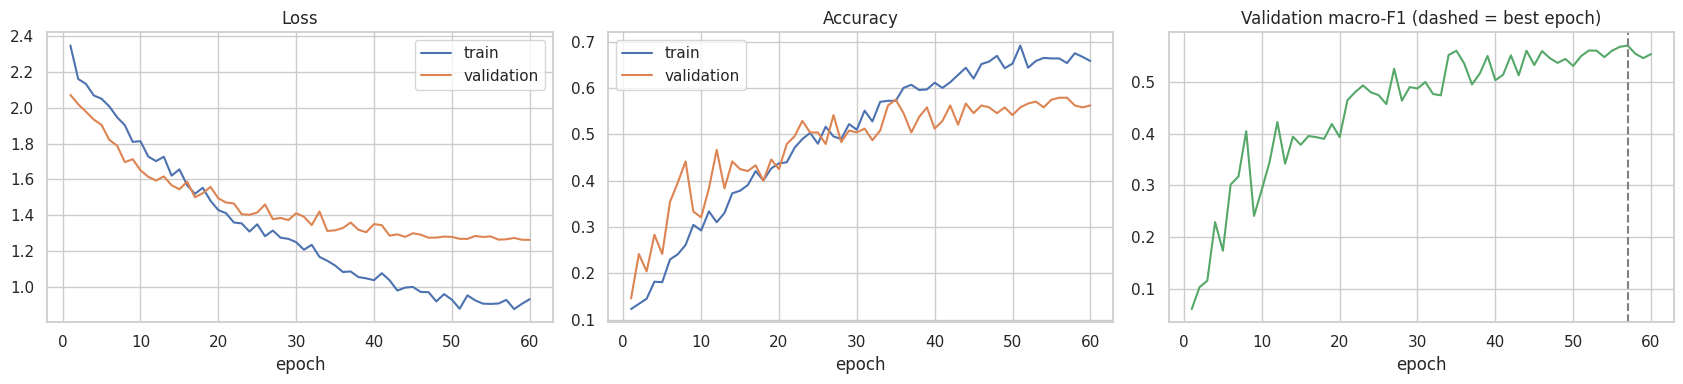

['tuning_results.csv', 'tuning_val_f1.png', 'cnn_seed0.pt', 'history_seed0.csv', 'cnn_seed1.pt', 'history_seed1.csv', 'cnn_seed2.pt', 'history_seed2.csv', 'cnn_best.pt', 'history.csv', 'final_summary.json', 'training_curves.png']


In [ ]:
import shutil
shutil.copy(chosen["ckpt"], f"{OUT}/cnn_best.pt")
chosen["history"].to_csv(f"{OUT}/history.csv", index=False)

summary = {"chosen_run": best_run, "config": {**best_cfg, "channels": list(best_cfg["channels"])},
           "chosen_seed": int(chosen["seed"]),
           "seeds": [{"seed": r["seed"], "val_macro_f1": r["val_macro_f1"], "val_acc": r["val_acc"], "best_epoch": r["best_epoch"]} for r in final],
           "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "batch": BATCH, "quick_dry_run": QUICK,
           "selection_data": "validation actors 3, 6, 15, 20 only"}
json.dump(summary, open(f"{OUT}/final_summary.json", "w"), indent=2)

h = chosen["history"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(h["epoch"], h["train_loss"], label="train"); axes[0].plot(h["epoch"], h["val_loss"], label="validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(h["epoch"], h["train_acc"], label="train"); axes[1].plot(h["epoch"], h["val_acc"], label="validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
axes[2].plot(h["epoch"], h["val_macro_f1"], color="#55A868"); axes[2].axvline(h["val_macro_f1"].idxmax() + 1, ls="--", color="gray")
axes[2].set_title("Validation macro-F1 (dashed = best epoch)"); axes[2].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(f"{OUT}/training_curves.png", dpi=140); plt.show()
print(os.listdir(OUT))

## 9. Check that the saved checkpoint works



In [ ]:
model, ckpt = load_checkpoint(f"{OUT}/cnn_best.pt", device)
loss, acc, f1 = evaluate_split(model, Xva, yva, nn.CrossEntropyLoss(weight=class_weights))
print(f"reloaded checkpoint: val accuracy {acc:.4f}, val macro-F1 {f1:.4f}")
print(f"recorded at training: val accuracy {chosen['val_acc']:.4f}, val macro-F1 {chosen['val_macro_f1']:.4f}")
assert abs(f1 - chosen["val_macro_f1"]) < 1e-4, "checkpoint does not reproduce the validation score!"
print("OK: checkpoint reproduces the validation score.")
print("stored normalization mean/std:", ckpt["norm_mean"], ckpt["norm_std"])

reloaded checkpoint: val accuracy 0.5792, val macro-F1 0.5702
recorded at training: val accuracy 0.5792, val macro-F1 0.5702
OK: checkpoint reproduces the validation score.
stored normalization mean/std: -17.16471290588379 15.781036376953125
